# 08 · Check W: is there a wetland signal in AlphaEarth? (post hoc, information only)

Matt asked: *does the AlphaEarth vector have enough signal to identify wetlands? If we use the vectors of known
wetlands to find other wetlands, does it work? Can't we sum all the wetland vectors to get "the" wetland vector?*

This notebook measures that directly (design written in `PLAN.md`, "Check W", before running; no pass marks).
Examples of wetland come from the training tiles; the score is how well each method ranks the pixels of **other**
tiles: the pool's test tiles and its held-out state.

Methods, from simplest to strongest:
1. **one example** pixel, cosine similarity (30 different examples);
2. **mean of 10 examples** (30 draws);
3. **mean of all** training wetland pixels (the "sum of the wetland vectors");
4. **wetland direction**: mean of wetland pixels minus mean of the other pixels;
5. **8 wetland vectors** (k-means centres), best match to any;
6. **nearest neighbours** (25), from 20,000 wetland and 20,000 other examples;
7. **linear classifier** (logistic regression) on the same examples;
8. **local ceiling**: linear classifier trained on the west half of the scored tiles, scored on the east half.

Scores: **average precision** (AP; chance = the wetland share) and the **best F1** over thresholds.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score

from askmap.config import PROJECT_ROOT, data_root, load_config
from askmap.layers import SOLAR_LATER, official_leaf_map
from askmap.models import pixels, unit
from askmap.signal import (
    best_f1,
    direction_scores,
    kmeans_centres,
    knn_scores,
    linear_scores,
    prototype_scores,
    west_half,
)
from askmap.tiles import area_tiles

cfg = load_config(PROJECT_ROOT / "configs" / "feasibility.yaml")
ROOT = data_root()
RES = PROJECT_ROOT / "outputs" / "results"
FIG = PROJECT_ROOT / "outputs" / "figures"
CL = cfg["classes"]
LEAVES = CL["leaves"]
WET = LEAVES.index("wetland")
CDL_WET = CL["cdl"]["wetland_cdl"]
N_SCORE, N_EX, N_DRAWS, K_CENTRES, K_NN, SEED = 100_000, 20_000, 30, 8, 25, 0
T_START = time.time()


def load(area: str, role: str) -> list[dict]:
    out = []
    for name, (_tile, r) in area_tiles(cfg["areas"][area], cfg["grid"]).items():
        if r != role:
            continue
        z = np.load(ROOT / "tiles" / f"{area}_{name}.npz")
        ae = z["ae"].astype(np.float32)
        solar = z["solar"] if "solar" in z.files else None
        nwi = z["nwi"] if "nwi" in z.files else None
        valid = np.isfinite(ae).all(axis=0)
        if solar is not None:
            valid &= solar != SOLAR_LATER
        leaf = official_leaf_map(z["cdl"], LEAVES, CL, nwi=nwi, solar=solar)
        out.append(
            {"name": name, "ae": ae, "valid": valid, "nwi": leaf == WET, "cdl": np.isin(z["cdl"], CDL_WET)}
        )
    if not out:
        raise ValueError(f"no {role} tiles for {area}")
    return out


def stack(tiles: list[dict], truth: str, where=None) -> tuple[np.ndarray, np.ndarray]:
    xs, ys = [], []
    for t in tiles:
        m = t["valid"] if where is None else t["valid"] & where(t["valid"].shape)
        xs.append(pixels(t["ae"])[m.ravel()])
        ys.append(t[truth][m])
    return np.concatenate(xs), np.concatenate(ys)


def sample(x: np.ndarray, y: np.ndarray, n: int, rng) -> tuple[np.ndarray, np.ndarray]:
    idx = rng.choice(len(x), size=min(n, len(x)), replace=False)
    return x[idx], y[idx]


TILES = {
    "north_dakota": {"train": load("north_dakota", "train"), "test": load("north_dakota", "test")},
    "north_carolina": {"train": load("north_carolina", "train"), "test": load("north_carolina", "test")},
    "minnesota": {"test": load("minnesota", "test")},
    "georgia": {"test": load("georgia", "test")},
}
print({a: {r: [t["name"] for t in ts] for r, ts in v.items()} for a, v in TILES.items()})

{'north_dakota': {'train': ['Stutsman', 'Barnes', 'Wells'], 'test': ['Kidder', 'Foster', 'Eddy']}, 'north_carolina': {'train': ['NC1', 'NC2', 'NC3'], 'test': ['NC4', 'NC5', 'NC6']}, 'minnesota': {'test': ['MN1', 'MN2', 'MN3']}, 'georgia': {'test': ['GA1', 'GA2', 'GA3']}}


## Scenarios

- **North Dakota, NWI wetlands** (the definition used in A2): examples and truth from the National Wetlands
  Inventory; scored on the North Dakota test tiles.
- **North Dakota, CDL wetlands**: examples and truth from the crop map's wetland classes (190/195); scored on the
  North Dakota test tiles and on Minnesota (whose truth in A2 was also CDL).
- **North Carolina, CDL wetlands**: scored on the North Carolina test tiles and on Georgia.

In [2]:
SCEN = [
    ("North Dakota, NWI", "north_dakota", "nwi", [("North Dakota test", "north_dakota")]),
    (
        "North Dakota, CDL",
        "north_dakota",
        "cdl",
        [("North Dakota test", "north_dakota"), ("Minnesota", "minnesota")],
    ),
    (
        "North Carolina, CDL",
        "north_carolina",
        "cdl",
        [("North Carolina test", "north_carolina"), ("Georgia", "georgia")],
    ),
]


def score(y: np.ndarray, s: np.ndarray) -> tuple[float, float]:
    return float(average_precision_score(y, s)), best_f1(y, s)


rows = []
for scen, pool, truth, scored in SCEN:
    rng = np.random.default_rng(SEED)
    xtr, ytr = stack(TILES[pool]["train"], truth)
    pos_all, neg_all = unit(xtr[ytr]), unit(xtr[~ytr])
    pos = pos_all[rng.choice(len(pos_all), size=min(N_EX, len(pos_all)), replace=False)]
    neg = neg_all[rng.choice(len(neg_all), size=min(N_EX, len(neg_all)), replace=False)]
    centres = kmeans_centres(pos, K_CENTRES, SEED)
    singles = rng.choice(len(pos_all), size=N_DRAWS, replace=False)
    tens = [rng.choice(len(pos_all), size=10, replace=False) for _ in range(N_DRAWS)]
    for set_name, area in scored:
        xs, ys = sample(*stack(TILES[area]["test"], truth), N_SCORE, rng)
        xs = unit(xs)
        base = {
            "scenario": scen,
            "scored": set_name,
            "wetland_share": float(ys.mean()),
            "train_wetland_px": len(pos_all),
        }
        one = np.array([score(ys, prototype_scores(xs, pos_all[i])) for i in singles])
        ten = np.array([score(ys, prototype_scores(xs, pos_all[i].mean(axis=0))) for i in tens])
        for method, arr in [("1 one example", one), ("2 mean of 10 examples", ten)]:
            rows.append(
                base
                | {
                    "method": method,
                    "AP": float(np.median(arr[:, 0])),
                    "AP_min": float(arr[:, 0].min()),
                    "AP_max": float(arr[:, 0].max()),
                    "best_F1": float(np.median(arr[:, 1])),
                }
            )
        for method, s in [
            ("3 mean of all wetland pixels", prototype_scores(xs, pos_all.mean(axis=0))),
            ("4 wetland direction", direction_scores(xs, pos_all, neg_all)),
            ("5 eight wetland vectors", prototype_scores(xs, centres)),
            ("6 nearest neighbours", knn_scores(pos, neg, xs, K_NN)),
            ("7 linear classifier", linear_scores(pos, neg, xs)),
        ]:
            ap, f = score(ys, s)
            rows.append(base | {"method": method, "AP": ap, "best_F1": f})
        # 8: local ceiling, west half of the scored tiles -> east half
        xw, yw = stack(TILES[area]["test"], truth, where=west_half)
        xe, ye = sample(*stack(TILES[area]["test"], truth, where=lambda sh: ~west_half(sh)), N_SCORE, rng)
        xw = unit(xw)
        pw = xw[yw][rng.choice(int(yw.sum()), size=min(N_EX, int(yw.sum())), replace=False)]
        nw = xw[~yw][rng.choice(int((~yw).sum()), size=min(N_EX, int((~yw).sum())), replace=False)]
        ap, f = score(ye, linear_scores(pw, nw, unit(xe)))
        rows.append(
            base
            | {
                "method": "8 local ceiling (west->east)",
                "AP": ap,
                "best_F1": f,
                "wetland_share_east": float(ye.mean()),
            }
        )
        print(f"{scen} | {set_name}: done ({time.time() - T_START:.0f} s)")

W = pd.DataFrame(rows)
W.to_csv(RES / "08_wetland_signal.csv", index=False)
W.pivot_table(index="method", columns=["scenario", "scored"], values="AP").round(3)

North Dakota, NWI | North Dakota test: done (33 s)


North Dakota, CDL | North Dakota test: done (65 s)


North Dakota, CDL | Minnesota: done (101 s)


North Carolina, CDL | North Carolina test: done (131 s)


North Carolina, CDL | Georgia: done (158 s)


scenario                     North Carolina, CDL                      \
scored                                   Georgia North Carolina test   
method                                                                 
1 one example                              0.524               0.606   
2 mean of 10 examples                      0.659               0.718   
3 mean of all wetland pixels               0.664               0.718   
4 wetland direction                        0.499               0.792   
5 eight wetland vectors                    0.522               0.610   
6 nearest neighbours                       0.649               0.799   
7 linear classifier                        0.687               0.815   
8 local ceiling (west->east)               0.863               0.855   

scenario                     North Dakota, CDL                    \
scored                               Minnesota North Dakota test   
method                                                             
1 one example                            0.197             0.467   
2 mean of 10 examples                    0.251             0.697   
3 mean of all wetland pixels             0.264             0.719   
4 wetland direction                      0.468             0.736   
5 eight wetland vectors                  0.176             0.619   
6 nearest neighbours                     0.405             0.799   
7 linear classifier                      0.555             0.843   
8 local ceiling (west->east)             0.778             0.814   

scenario                     North Dakota, NWI  
scored                       North Dakota test  
method                                          
1 one example                            0.361  
2 mean of 10 examples                    0.494  
3 mean of all wetland pixels             0.504  
4 wetland direction                      0.606  
5 eight wetland vectors                  0.383  
6 nearest neighbours                     0.567  
7 linear classifier                      0.608  
8 local ceiling (west->east)             0.679

## Best F1 (the best balance of finding wetlands and not marking other land)

In [3]:
W.pivot_table(index="method", columns=["scenario", "scored"], values="best_F1").round(3)

scenario                     North Carolina, CDL                      \
scored                                   Georgia North Carolina test   
method                                                                 
1 one example                              0.579               0.631   
2 mean of 10 examples                      0.626               0.697   
3 mean of all wetland pixels               0.627               0.697   
4 wetland direction                        0.615               0.718   
5 eight wetland vectors                    0.578               0.598   
6 nearest neighbours                       0.657               0.744   
7 linear classifier                        0.670               0.741   
8 local ceiling (west->east)               0.782               0.769   

scenario                     North Dakota, CDL                    \
scored                               Minnesota North Dakota test   
method                                                             
1 one example                            0.277             0.541   
2 mean of 10 examples                    0.311             0.684   
3 mean of all wetland pixels             0.319             0.700   
4 wetland direction                      0.493             0.704   
5 eight wetland vectors                  0.256             0.608   
6 nearest neighbours                     0.415             0.776   
7 linear classifier                      0.545             0.776   
8 local ceiling (west->east)             0.701             0.752   

scenario                     North Dakota, NWI  
scored                       North Dakota test  
method                                          
1 one example                            0.467  
2 mean of 10 examples                    0.552  
3 mean of all wetland pixels             0.569  
4 wetland direction                      0.611  
5 eight wetland vectors                  0.444  
6 nearest neighbours                     0.606  
7 linear classifier                      0.620  
8 local ceiling (west->east)             0.654

In [4]:
W.groupby(["scenario", "scored"])[["wetland_share", "train_wetland_px"]].first().round(3)

wetland_share  train_wetland_px
scenario            scored                                              
North Carolina, CDL Georgia                      0.224            340394
                    North Carolina test          0.217            340394
North Dakota, CDL   Minnesota                    0.056             76169
                    North Dakota test            0.092             76169
North Dakota, NWI   North Dakota test            0.077             60928

In [5]:
d = W[W.method.str.startswith(("1", "2"))][["scenario", "scored", "method", "AP", "AP_min", "AP_max"]]
d.round(3)

,scenario,scored,method,AP,AP_min,AP_max
0,"North Dakota, NWI",North Dakota test,1 one example,0.361,0.069,0.636
1,"North Dakota, NWI",North Dakota test,2 mean of 10 examples,0.494,0.328,0.567
8,"North Dakota, CDL",North Dakota test,1 one example,0.467,0.100,0.811
9,"North Dakota, CDL",North Dakota test,2 mean of 10 examples,0.697,0.522,0.768
16,"North Dakota, CDL",Minnesota,1 one example,0.197,0.049,0.395
17,"North Dakota, CDL",Minnesota,2 mean of 10 examples,0.251,0.136,0.319
24,"North Carolina, CDL",North Carolina test,1 one example,0.606,0.208,0.835
25,"North Carolina, CDL",North Carolina test,2 mean of 10 examples,0.718,0.520,0.808
32,"North Carolina, CDL",Georgia,1 one example,0.524,0.218,0.739
33,"North Carolina, CDL",Georgia,2 mean of 10 examples,0.659,0.492,0.711


total 158 s


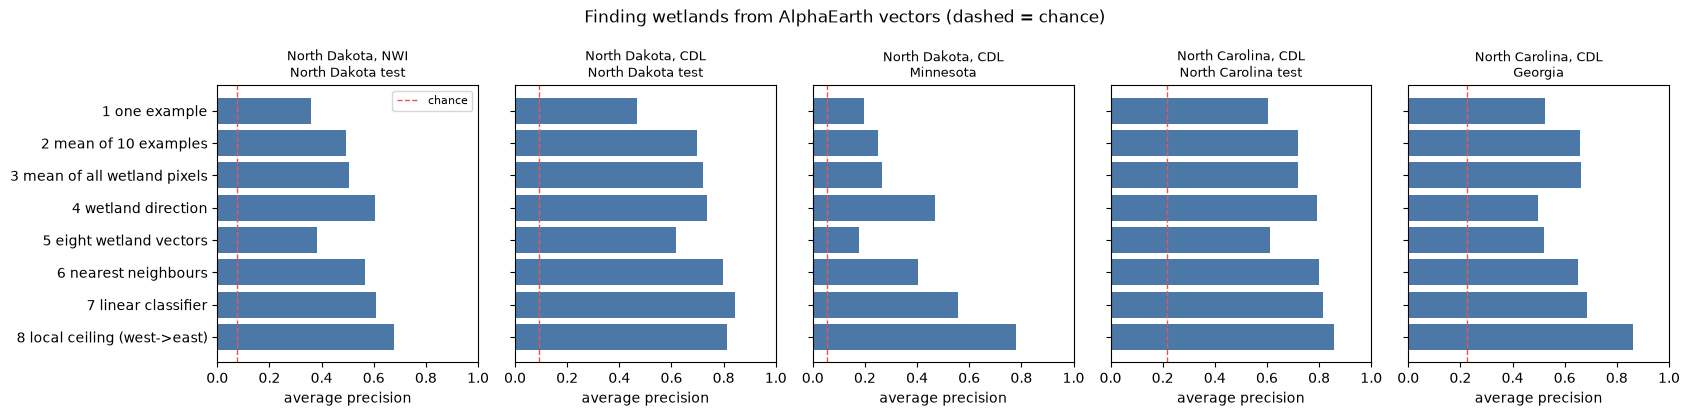

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(17, 4.2), sharey=True)
for ax, ((scen, scored), g) in zip(axes, W.groupby(["scenario", "scored"], sort=False), strict=True):
    g = g.sort_values("method")
    ax.barh(g["method"], g["AP"], color="#4c78a8")
    ax.axvline(g["wetland_share"].iloc[0], color="#e45756", ls="--", lw=1, label="chance")
    ax.set_title(f"{scen}\n{scored}", fontsize=9)
    ax.set_xlim(0, 1)
    ax.set_xlabel("average precision")
axes[0].invert_yaxis()
axes[0].legend(fontsize=8)
fig.suptitle("Finding wetlands from AlphaEarth vectors (dashed = chance)")
fig.tight_layout()
fig.savefig(FIG / "08_wetland_signal.png", dpi=130)
print(f"total {time.time() - T_START:.0f} s")